# MRI Reference Space and the Link to Histology

**C-Stroke · case HB02CV · reference notebook 4 of 4**

The C-Stroke platform shows the case's MRI and its histology in one **reference space**: an ex-vivo grid of 211 × 377 × 238 voxels (0.49 × 0.49 × 0.70 mm) into which all data are registered. It contains:

* in-vivo diffusion MRI (DWI and ADC) at two time points, 16 and 11 days before death (*dpm*, days pre-mortem);
* ex-vivo T1, T2 and diffusion MRI of the fixed brain;
* a histology volume reconstructed from the Nissl sections;
* lesion masks for the in-vivo and ex-vivo scans;
* anatomical (MNI-based) and arterial-territory label volumes;
* the geometry of the five histology blocks, which tells, for every voxel, which section of which block passes through it.

The platform's MRI viewer reads these files from `https://c-stroke.humanbrain.in/stroke_atlas/viewer/data/`. `ReferenceSpace` in `refspace_utils.py` reads the same files and decodes them the way the viewer does.

This notebook shows how to:

1. Inspect the series, lesion masks and blocks of the reference space.
2. View any volume in the three planes and compare series at one location.
3. Measure lesion masks and how they agree.
4. Attribute a lesion to anatomical regions and arterial territories.
5. Go from an MRI voxel to the histology section that passes through it, and sample the MRI along that section's plane.
6. Compare the infarct measured on histology with the lesions seen on MRI, section by section.

**Runtime:** a few minutes on a CPU. The volumes total about 40 MB compressed and are cached after the first run.

## 1. Setup

The notebook uses the helper modules of this repository. In a local clone they are found automatically. On Google Colab, Kaggle or any other fresh environment, the cell below clones the repository first. All data are read from the C-Stroke platform at `https://c-stroke.humanbrain.in` and cached under `~/.cache/cstroke`.

In [1]:
import os
import subprocess
import sys
from pathlib import Path

REPO_URL = "https://github.com/24f2007780/stroke_utils.git"

# Use the local repository (this notebook's parent folder) if present; otherwise clone it.
root = next((p for p in (Path.cwd(), Path.cwd().parent, Path.cwd() / "stroke_utils")
             if (p / "slide_utils.py").exists()), None)
if root is None:
    subprocess.run(["git", "clone", "-q", REPO_URL], check=True)
    root = Path.cwd() / "stroke_utils"
sys.path.insert(0, str(root))
print("Helper modules from", root)

Helper modules from /home/antareep/workspace/stroke_notebook/stroke_utils


In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Patch
from scipy import ndimage as ndi
from scipy import stats

import display_utils as du
from refspace_utils import ReferenceSpace
from slide_utils import BLOCKS, STAINS, SlideCatalog, SlideHelper

du.set_style()
pd.set_option("display.float_format", "{:.2f}".format)

rs = ReferenceSpace()
catalog = SlideCatalog()
VOXEL_ML = np.prod(rs.spacing) / 1000           # one voxel in millilitres

# Lesion mask used for anatomical attribution and the voxel-to-slide example (see Section 4)
LESION = "iv11_dwi_hyper"
print(rs)

ReferenceSpace(grid 211 x 377 x 238 voxels, 0.488 x 0.488 x 0.70 mm)


## 2. What the reference space contains

### 2.1 Intensity series, lesion masks and blocks

`series()` lists the intensity volumes with their time point and the blocks they cover. The in-vivo scans do not cover the whole brain: the 11 dpm ADC, for example, exists only for the left-hemisphere blocks. `lesion_masks()` and `blocks()` list the lesion masks and the histology blocks with their extent along the cutting axis.

In [3]:
display(rs.series())
display(rs.lesion_masks())
rs.blocks()

,name,description,timepoint,sequence,range,blocks
0,iv11_DWI,DWI · 11 dpm,11dpm,DWI,"(0.0038826596573926504, 258.52217483520536)","218, 217, 313, 315, 314"
1,iv11_ADC,ADC · 11 dpm,11dpm,ADC,"(0.0300023203343153, 2578.153242187502)","313, 315, 314"
2,iv16_DWI,DWI · 16 dpm,16dpm,DWI,"(0.0010480805346742273, 196.8342742919922)","218, 217, 313, 315, 314"
3,iv16_ADC,ADC · 16 dpm,16dpm,ADC,"(0.04211093880236148, 2592.08642578125)","218, 217, 313, 315, 314"
4,ex_T2,ex-vivo T2,ex vivo,T2,"(8.0, 620.0)",all
5,ex_DWI,ex-vivo DWI,ex vivo,DWI,"(61.0, 2644.0)",all
6,ex_T1,ex-vivo T1,ex vivo,T1,"(817.0, 15728.0)",all
7,histo,histology (Nissl merge),,histo,"(0.0, 176.93503906249975)",all


,id,description,timepoint
0,iv16_dwi_hyper,DWI hyperintensity · in-vivo 16 dpm,16dpm
1,iv16_adc_hypo,ADC hypointensity · in-vivo 16 dpm,16dpm
2,iv11_dwi_hyper,DWI hyperintensity · in-vivo 11 dpm,11dpm
3,iv11_adc_hypo,ADC hypointensity · in-vivo 11 dpm,11dpm
4,ex_dwi_hyper,DWI hyperintensity · ex-vivo,ex vivo
5,ex_adc_hypo,ADC hypointensity · ex-vivo,ex vivo
6,ex_t2_hyper,T2 hyperintensity · ex-vivo,ex vivo


,block,position,sections,mm_from,mm_to,grid_slices
0,314,left lateral,1-1518,0.02,30.36,64
1,315,left mid,1-1032,30.38,51.00,43
2,313,left medial,1-1887,51.02,88.74,79
3,217,right medial,1-1805,88.76,124.84,75
4,218,right lateral,1-2049,124.86,165.82,86


### 2.2 Blocks and stains along the left–right axis

The blocks are consecutive slabs along the left–right axis (`k`), and every histology section is a near-sagittal plane through them. `block_map()` assigns each voxel to the block it lies in, the same way the platform viewer does. The left panel shows this on an axial slice. `stains_by_global_section()` lists which stains exist at each of the 8,291 global section positions (one per 20 µm). The right panel shows them along the same axis.

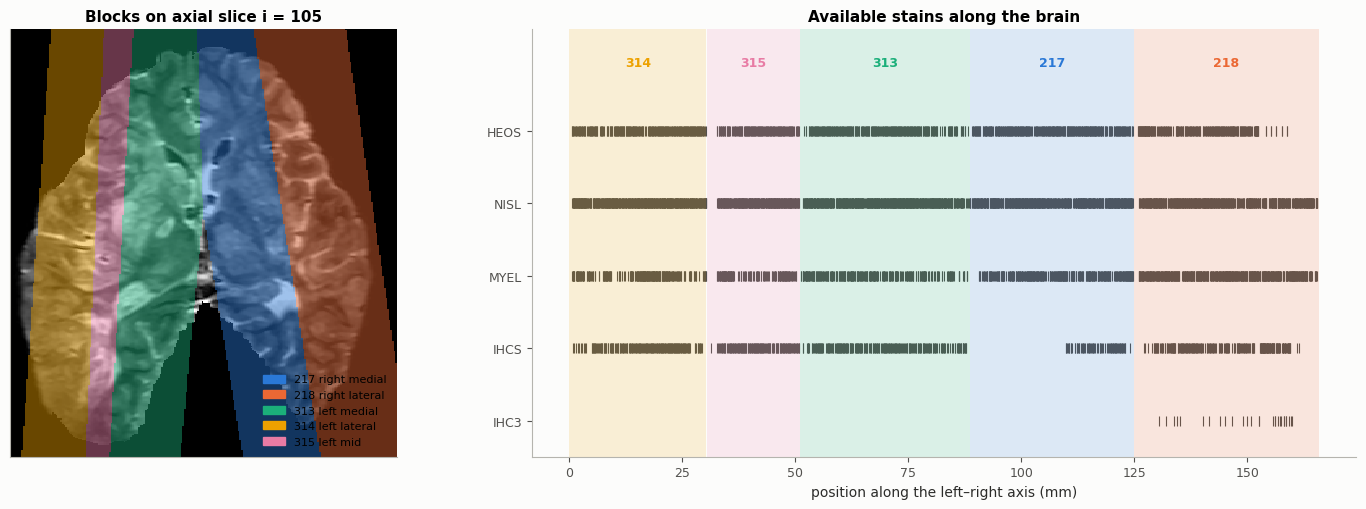

In [4]:
owner, block_coord = rs.block_map()
t2 = rs.volume("ex_T2")
mid_i = rs.shape[0] // 2
block_list = sorted(BLOCKS)
block_colors = dict(zip(block_list, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5.2), gridspec_kw={"width_ratios": [1, 1.3]})
du.show_refspace(ax1, t2, "axial", mid_i, rs.spacing, title=f"Blocks on axial slice i = {mid_i}")
overlay = np.full(owner.shape[1:] + (4,), 0.0)
for b, c in block_colors.items():
    overlay[owner[mid_i] == b] = plt.matplotlib.colors.to_rgba(c, 0.45)
ax1.imshow(overlay, aspect=rs.spacing[1] / rs.spacing[2])
ax1.legend(handles=[Patch(color=c, label=f"{b} {BLOCKS[b]}") for b, c in block_colors.items()], loc="lower right",
           fontsize=8)

stains = rs.stains_by_global_section()
names = rs.manifest["stains"]
for lane, name in enumerate(names):
    gid = stains.global_id[stains[name]]
    ax2.scatter(gid * 0.02, np.full(len(gid), lane), marker="|", s=60, lw=0.8, color="#52514e")
for _, b in rs.blocks().iterrows():
    ax2.axvspan(b.mm_from, b.mm_to, color=block_colors[b.block], alpha=0.15, lw=0)
    ax2.text((b.mm_from + b.mm_to) / 2, -0.9, str(b.block), ha="center", fontsize=9, color=block_colors[b.block],
             fontweight="bold")
ax2.set_yticks(range(len(names)), names)
ax2.set_ylim(len(names) - 0.5, -1.4)
ax2.set_xlabel("position along the left–right axis (mm)")
ax2.set_title("Available stains along the brain")
plt.tight_layout()
plt.show()

## 3. Viewing volumes

`volume(name)` returns an intensity volume in its original units, indexed `[i, j, k]` (`i` inferior→superior, `j` anterior→posterior, `k` left→right). Voxels outside the blocks a series was acquired in are `NaN` and shown as dark grey. `display_utils.show_refspace` draws a slice in anatomical orientation with millimetre proportions.

The crosshair is placed at the centre of the 11 dpm DWI lesion mask. The figure shows the same location on every series.

crosshair at voxel i=135, j=255, k=62 -> [150.9 143.6  43.4] mm


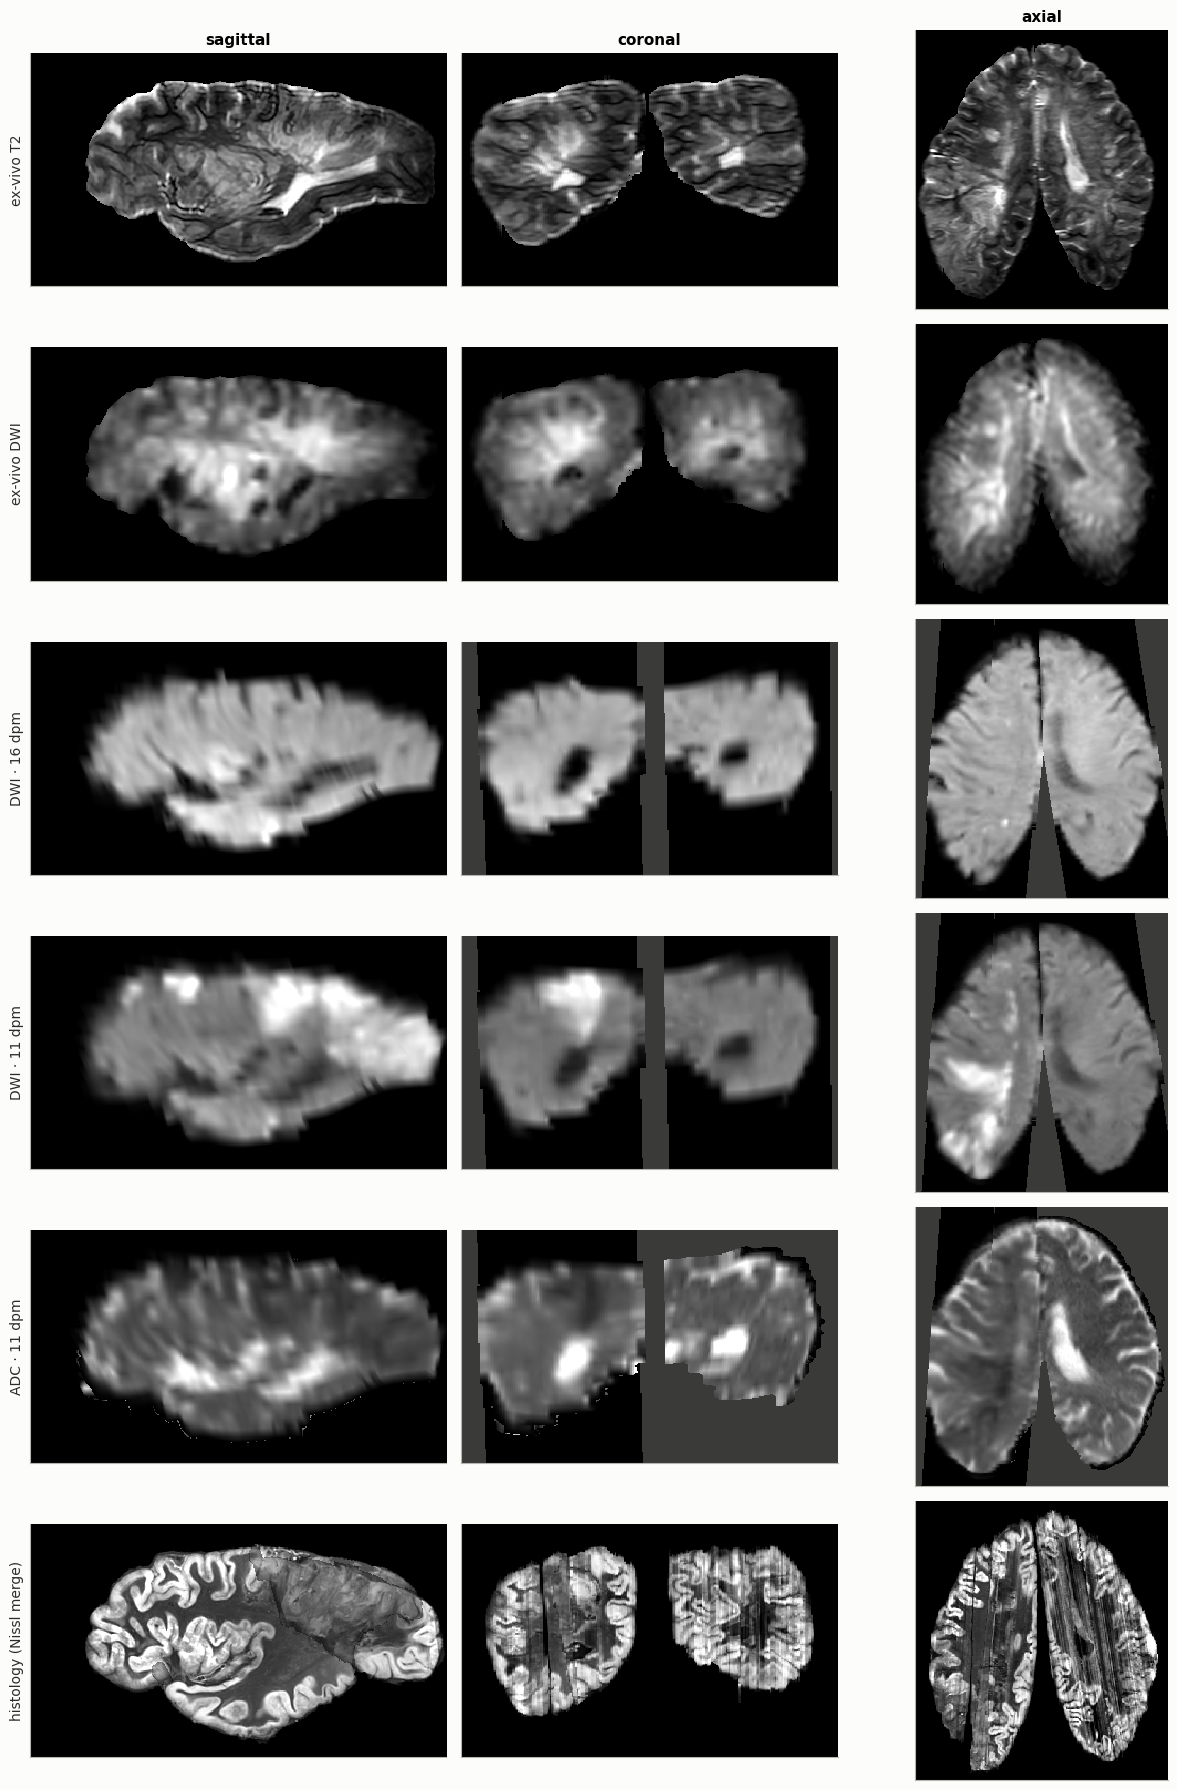

In [5]:
lesion = rs.lesion_mask(LESION)
ci, cj, ck = np.round(ndi.center_of_mass(lesion)).astype(int)
print(f"crosshair at voxel i={ci}, j={cj}, k={ck} -> {np.round(rs.voxel_mm(ci, cj, ck), 1)} mm")

show = ["ex_T2", "ex_DWI", "iv16_DWI", "iv11_DWI", "iv11_ADC", "histo"]
descriptions = rs.series().set_index("name").description
cmap = plt.get_cmap("gray").copy()
cmap.set_bad("#3a3a38")
fig, axes = plt.subplots(len(show), 3, figsize=(12.5, 3.0 * len(show)),
                         gridspec_kw={"width_ratios": [rs.shape[1] * rs.spacing[1], rs.shape[2] * rs.spacing[2],
                                                       rs.shape[2] * rs.spacing[2]]})
for r, name in enumerate(show):
    vol = rs.volume(name)
    lo, hi = np.nanpercentile(vol[np.isfinite(vol) & (vol > np.nanmin(vol))], [1, 99.5])
    for c, (plane, index) in enumerate([("sagittal", ck), ("coronal", cj), ("axial", ci)]):
        ax = axes[r, c]
        du.show_refspace(ax, vol, plane, index, rs.spacing, cmap=cmap, vmin=lo, vmax=hi)
        if r == 0:
            ax.set_title(plane)
    axes[r, 0].set_ylabel(descriptions[name], fontsize=10)
plt.tight_layout()
plt.show()

## 4. Lesion masks

`lesion_mask(id)` returns a boolean volume. The masks delineate different signals: DWI hyperintensity and ADC hypointensity on the in-vivo scans at each time point, and DWI, ADC and T2 abnormalities on the ex-vivo scan. Their volumes, and how much they overlap (Dice coefficient), show how the visible lesion depends on the scan and on time.

,description,volume (mL)
iv16_dwi_hyper,DWI hyperintensity · in-vivo 16 dpm,0.96
iv16_adc_hypo,ADC hypointensity · in-vivo 16 dpm,1.71
iv11_dwi_hyper,DWI hyperintensity · in-vivo 11 dpm,94.78
iv11_adc_hypo,ADC hypointensity · in-vivo 11 dpm,26.42
ex_dwi_hyper,DWI hyperintensity · ex-vivo,25.31
ex_adc_hypo,ADC hypointensity · ex-vivo,8.65
ex_t2_hyper,T2 hyperintensity · ex-vivo,23.64


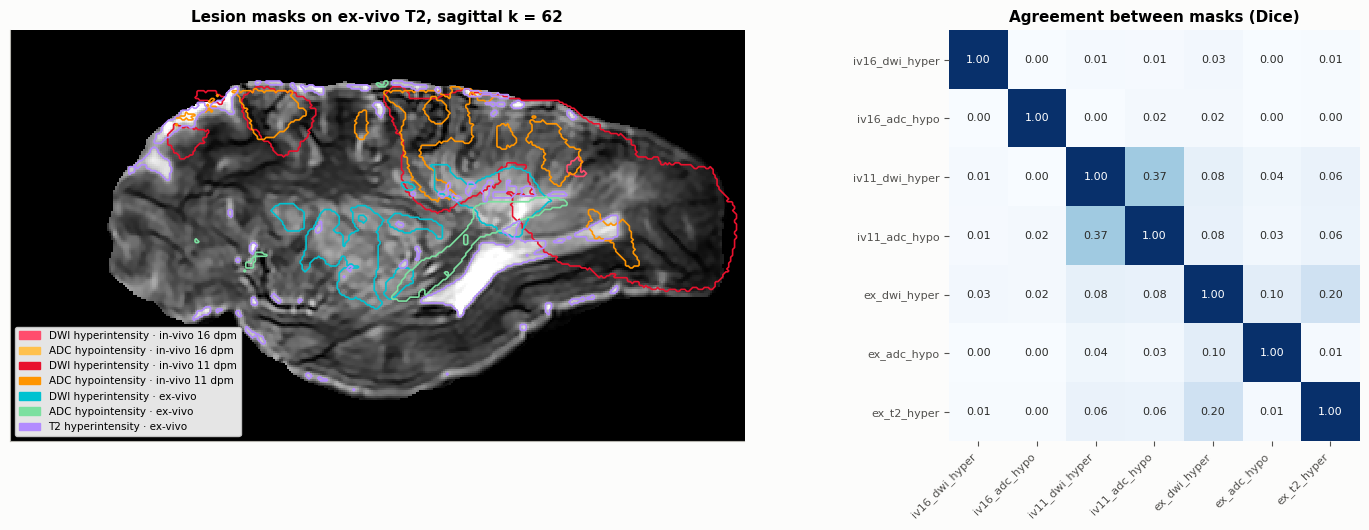

In [6]:
masks = {m: rs.lesion_mask(m) for m in rs.lesion_masks().id}
labels_ = rs.lesion_masks().set_index("id").description
volumes = pd.DataFrame({"description": labels_, "volume (mL)": {m: v.sum() * VOXEL_ML for m, v in masks.items()}})
ids = list(masks)
dice = pd.DataFrame([[2 * (masks[a] & masks[b]).sum() / max(masks[a].sum() + masks[b].sum(), 1) for b in ids]
                     for a in ids], index=ids, columns=ids)
display(volumes)

fig, axes = plt.subplots(1, 2, figsize=(15, 5.4), gridspec_kw={"width_ratios": [1.25, 1]})
du.show_refspace(axes[0], t2, "sagittal", ck, rs.spacing, cmap=cmap, title=f"Lesion masks on ex-vivo T2, sagittal k = {ck}")
mask_colors = {m["id"]: m["color"] for m in rs.manifest["segs"]}
for m, v in masks.items():
    sl = v[::-1, :, ck].astype(float)
    if sl.any():
        axes[0].contour(sl, levels=[0.5], colors=[mask_colors[m]], linewidths=1.2)
axes[0].legend(handles=[Patch(color=mask_colors[m], label=labels_[m]) for m in ids], fontsize=7.5, loc="lower left",
               frameon=True, facecolor="white", framealpha=0.9)
axes[1].imshow(dice.values, cmap="Blues", vmin=0, vmax=1)
axes[1].set_xticks(range(len(ids)), ids, rotation=45, ha="right", fontsize=8)
axes[1].set_yticks(range(len(ids)), ids, fontsize=8)
for (r, c), v in np.ndenumerate(dice.values):
    axes[1].text(c, r, f"{v:.2f}", ha="center", va="center", fontsize=8, color="white" if v > 0.55 else "#2b2b29")
axes[1].set_title("Agreement between masks (Dice)")
axes[1].spines[:].set_visible(False)
plt.tight_layout()
plt.show()

## 5. Anatomical and vascular attribution

`labels("mni")` and `labels("art")` return the anatomical and arterial-territory label volumes, and `label_names()` gives their names. The arterial atlas as delivered is mirrored left to right (a note in the platform's manifest). `label_names("art")` therefore swaps the side words by default, as the platform viewer does.

For the lesion mask `LESION`, the tables list the regions and territories holding most of the lesion volume, and the share of each region that the lesion occupies.

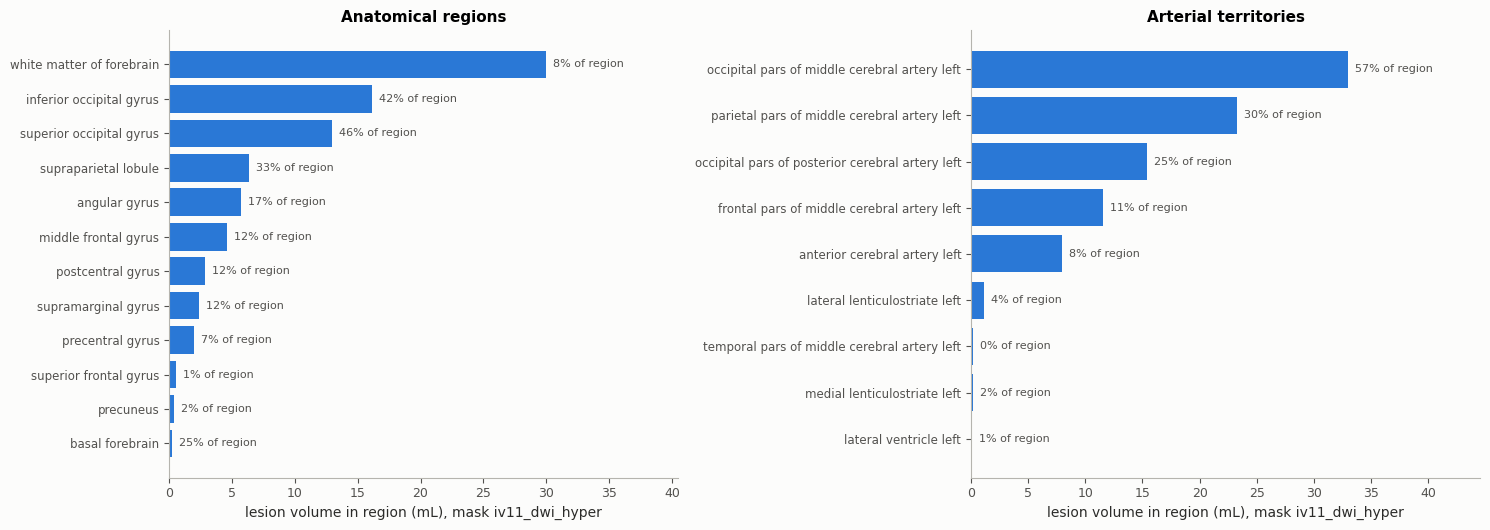

In [7]:
def attribution(atlas, mask, top=12):
    lab = rs.labels(atlas)
    names = rs.label_names(atlas).set_index("id")
    inside = np.bincount(lab[mask], minlength=256)
    total = np.bincount(lab.ravel(), minlength=256)
    rows = [{"region": names.loc[i, "name"], "lesion (mL)": inside[i] * VOXEL_ML,
             "share of lesion": inside[i] / mask.sum(), "share of region": inside[i] / total[i],
             "color": names.loc[i, "color"]}
            for i in np.flatnonzero(inside) if i in names.index]
    return pd.DataFrame(rows).sort_values("lesion (mL)", ascending=False).head(top).reset_index(drop=True)


regions = attribution("mni", lesion)
territories = attribution("art", lesion)

fig, axes = plt.subplots(1, 2, figsize=(15, 5.4))
for ax, table, title in [(axes[0], regions, "Anatomical regions"), (axes[1], territories, "Arterial territories")]:
    ax.barh(table.region, table["lesion (mL)"], color="#2a78d6")
    for y, (v, s) in enumerate(zip(table["lesion (mL)"], table["share of region"])):
        ax.text(v, y, f"  {s:.0%} of region", va="center", fontsize=8, color="#52514e")
    ax.invert_yaxis()
    ax.set_xlabel(f"lesion volume in region (mL), mask {LESION}")
    ax.set_title(title)
    ax.set_xlim(0, table["lesion (mL)"].max() * 1.35)
    ax.tick_params(axis="y", labelsize=8.5)
plt.tight_layout()
plt.show()

## 6. From an MRI voxel to a histology slide

The block geometry links every voxel to a section. `section_at(i, j, k)` returns the block and section number that pass through a voxel. `catalog.nearest` then finds the nearest slide of each stain. Going the other way, `sample_on_section(volume, block, section)` samples any volume along the oblique plane of a section. This gives the MRI as it would appear on that slide.

The example takes a lesion voxel inside the left-hemisphere blocks (where H&E infarct outlines exist) and shows the MRI planes next to the H&E slide of the same section.

In [8]:
candidates = np.argwhere(lesion & np.isin(owner, [313, 314, 315]))
target = candidates[np.argmin(np.abs(candidates - np.array([ci, cj, ck])).sum(axis=1))]
block, section = rs.section_at(*target)
print(f"voxel {tuple(target)} lies on block {block} ({BLOCKS[block]}), section {section}")

near = catalog.neighbours(block, section, max_gap=50)
he_row = catalog.nearest(block, section, "HE", annotated=True)
print(f"nearest infarct-annotated H&E section: {he_row.section} ({abs(he_row.gap_sections) * 20} um away)")
near[["stain", "marker", "section", "distance_um"]]

voxel (135, 255, 63) lies on block 315 (left mid), section 752
nearest infarct-annotated H&E section: 740 (240 um away)


,stain,marker,section,distance_um
0,N,None,745,140
1,IHC,CD68,743,180
2,HE,None,740,240
3,IHC,CD34,737,300
4,IHC,GAP43,767,300
5,IHC,APP,779,540
6,IHC,FIB,791,780
7,IHC,GFAP,797,900


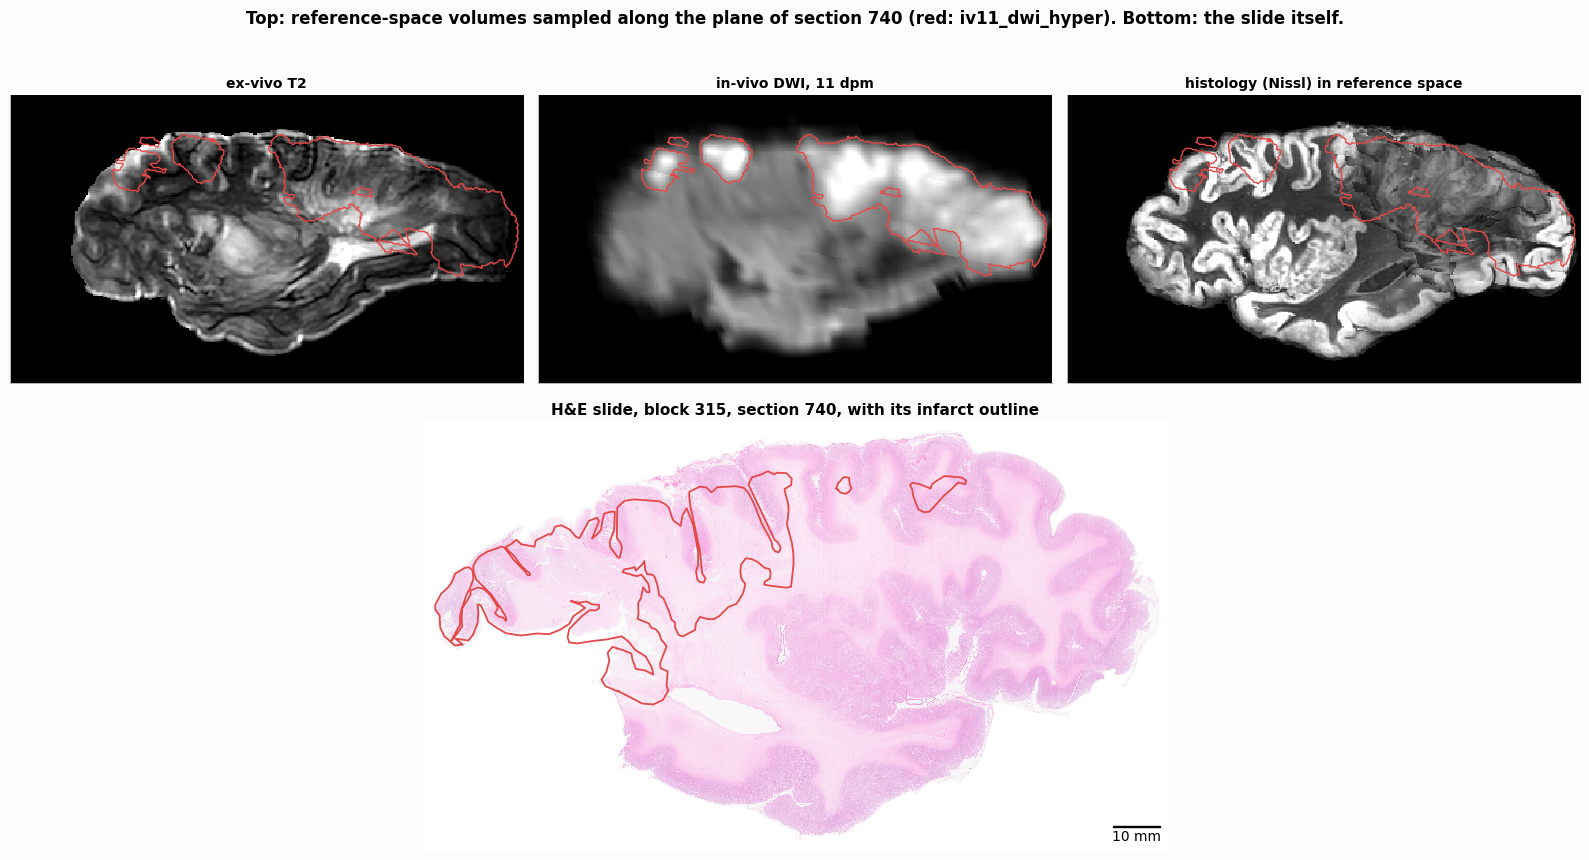

In [9]:
planes = {"ex-vivo T2": rs.volume("ex_T2"), "in-vivo DWI, 11 dpm": rs.volume("iv11_DWI"),
          "histology (Nissl) in reference space": rs.volume("histo")}
lesion_plane = rs.sample_on_section(lesion.astype(float), he_row.block, he_row.section)
aspect = rs.spacing[0] / rs.spacing[1]

fig = plt.figure(figsize=(16, 8.6))
grid = fig.add_gridspec(2, 3, height_ratios=[1, 1.15])
for c, (title, vol) in enumerate(planes.items()):
    ax = fig.add_subplot(grid[0, c])
    img = rs.sample_on_section(vol, he_row.block, he_row.section)
    lo, hi = np.nanpercentile(img[np.isfinite(img) & (img > np.nanmin(img))], [1, 99.5])
    ax.imshow(img[::-1], cmap=cmap, vmin=lo, vmax=hi, aspect=aspect)
    ax.contour(np.nan_to_num(lesion_plane[::-1]), levels=[0.5], colors=[du.INFARCT_COLOR], linewidths=1)
    ax.set_title(title, fontsize=10)
    ax.set_xticks([]); ax.set_yticks([])
ax = fig.add_subplot(grid[1, :])
he_helper = SlideHelper(block, "HE", catalog=catalog)
he_img, he_reg = he_helper.get_sectionimage(he_row.section)
du.show_image(ax, he_img, he_reg, f"H&E slide, block {block}, section {he_row.section}, with its infarct outline",
              bar_mm=10)
du.draw_annotation(ax, he_helper.get_annotation(he_row.section), he_reg, colors={1: du.INFARCT_COLOR}, linewidth=1.3)
plt.suptitle(f"Top: reference-space volumes sampled along the plane of section {he_row.section} "
             f"(red: {LESION}). Bottom: the slide itself.", fontweight="bold", y=0.995)
plt.tight_layout()
plt.show()

The top row is the section plane as seen in the reference space: the same tissue as the slide below, at MRI resolution. The slide images are shown as scanned, so their orientation and mirroring can differ from the reference-space view. The reconstructed histology volume (top right) shows how the slides were placed into the reference space.

## 7. Histology and MRI, section by section

The platform's manifest lists the infarct-annotated H&E sections, with a QC flag and the infarct area measured on each (`infarct_sections()`). Sampling each MRI lesion mask along the plane of the same section gives the lesion area seen on MRI at exactly that position. Plotting both along the blocks shows where the two modalities agree.

In [10]:
he = rs.infarct_sections()
he = he[he.qc == "PASS"].copy()
pixel_mm2 = rs.spacing[0] * rs.spacing[1]
compare = ["iv16_dwi_hyper", "iv11_dwi_hyper", "ex_dwi_hyper", "ex_t2_hyper"]
for m in compare:
    vol = masks[m].astype(np.float32)
    he[m] = [np.nansum(rs.sample_on_section(vol, b, s)) * pixel_mm2 for b, s in zip(he.block, he.section)]
print(f"{len(he)} H&E sections passing QC")
he[["block", "section", "position_mm", "infarct_area_mm2"] + compare].head()

147 H&E sections passing QC


,block,section,position_mm,infarct_area_mm2,iv16_dwi_hyper,iv11_dwi_hyper,ex_dwi_hyper,ex_t2_hyper
0,313,386,81.04,51.15,0.00,227.45,306.37,336.65
1,313,392,80.92,40.78,0.00,230.31,310.18,332.83
2,313,398,80.80,37.32,0.00,233.17,313.04,331.88
3,313,410,80.56,42.16,0.00,235.56,315.90,318.53
4,313,416,80.44,40.09,0.00,234.60,320.91,318.53


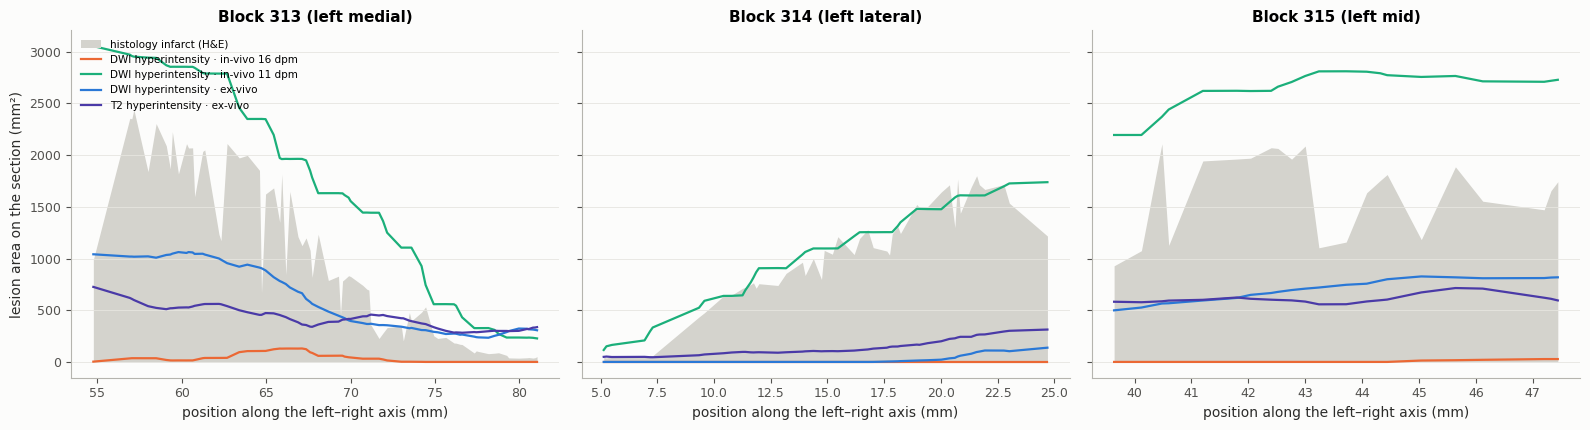

,Spearman ρ with histology,area ratio MRI / histology
DWI hyperintensity · in-vivo 16 dpm,0.29,0.02
DWI hyperintensity · in-vivo 11 dpm,0.86,1.48
DWI hyperintensity · ex-vivo,0.54,0.39
T2 hyperintensity · ex-vivo,0.53,0.33


In [11]:
blocks_with_infarct = sorted(he.block.unique())
mask_colors_plot = dict(zip(compare, ["#eb6834", "#1baf7a", "#2a78d6", "#4a3aa7"]))
fig, axes = plt.subplots(1, len(blocks_with_infarct), figsize=(16, 4.4), sharey=True)
for ax, b in zip(axes, blocks_with_infarct):
    t = he[he.block == b].sort_values("position_mm")
    ax.fill_between(t.position_mm, t.infarct_area_mm2, color="#d4d3cd", lw=0, label="histology infarct (H&E)")
    for m in compare:
        ax.plot(t.position_mm, t[m], lw=1.6, color=mask_colors_plot[m], label=labels_[m])
    ax.set_title(f"Block {b} ({BLOCKS[b]})")
    ax.set_xlabel("position along the left–right axis (mm)")
    ax.grid(axis="y")
axes[0].set_ylabel("lesion area on the section (mm²)")
axes[0].legend(fontsize=7.5, loc="upper left")
plt.tight_layout()
plt.show()

agreement = pd.DataFrame({m: [stats.spearmanr(he.infarct_area_mm2, he[m])[0],
                              he[m].sum() / he.infarct_area_mm2.sum()] for m in compare},
                         index=["Spearman ρ with histology", "area ratio MRI / histology"]).T
agreement.index = [labels_[m] for m in compare]
agreement

**Reading the comparison.**

* The **in-vivo DWI hyperintensity at 11 dpm** follows the histological infarct best along the blocks (Spearman ρ ≈ 0.86 across sections). It covers about 1.5 times the histological area. Diffusion changes extend beyond the tissue that is recognisably infarcted on H&E, and the in-vivo data, resampled from a block grid 2.2 mm thick (see the manifest notes), blur the outline.
* The **ex-vivo DWI and T2 masks** track the histological infarct less closely (ρ ≈ 0.5) and cover about a third of its area. These masks mark specific signal abnormalities of the fixed brain, not the full infarct.
* The **16 dpm masks** are very small (about 1–2 mL against about 95 mL at 11 dpm). On this case's diffusion scans, the lesion is visible mainly at 11 dpm.

The histological infarct volume estimated in `lesion_across_sections.ipynb` (about 60 mL in the three left-hemisphere blocks) lies between the ex-vivo masks and the 11 dpm DWI lesion. The section-by-section comparison shows *where* along the brain the modalities agree, which a single volume cannot.

## Summary

| Task | Call |
|---|---|
| Series, lesion masks, blocks | `rs.series()`, `rs.lesion_masks()`, `rs.blocks()` |
| Intensity volume in original units | `rs.volume(name)` (`[i, j, k]`, `NaN` outside coverage) |
| Lesion mask | `rs.lesion_mask(id)` |
| Anatomical and arterial labels | `rs.labels("mni" or "art")`, `rs.label_names(...)` |
| Stains available along the brain | `rs.stains_by_global_section()` |
| Block ownership of voxels | `rs.block_map()` |
| Section through a voxel | `rs.section_at(i, j, k)` |
| A volume along a section's plane | `rs.sample_on_section(volume, block, section)` |
| Infarct sections listed by the platform | `rs.infarct_sections()` |
| Display | `display_utils.show_refspace(ax, volume, plane, index, rs.spacing)` |

**Notes.** Volumes are stored as 8-bit values and rescaled to their original range, so intensities are quantised to 1/255 of that range. Areas sampled on section planes count voxels in the `i`–`j` grid. Because the planes are close to perpendicular to `k`, this approximates the area on the oblique plane.